In [1]:
%load_ext autoreload
%autoreload 2
from MATH_4511_functions import * 

## Problem Set 1

In [2]:
import matplotlib.pyplot as plt
import math

In [3]:
#Problem 1
T = 6
FV = 1000
c = 0.06
m = 4
i = 0.05 #current annual effective yield rate
#a) Find the current price of the bond
P0 = 0
for k in range(1, m*T+1):
    P0 += (FV*c/m)/(1+i)**(k/m)
P0 += FV/(1+i)**(6)
print(f'The current price is {P0} USD')
#b) The yield drops to 4.6% after 30 months, calculate the dirty and the clean price at that time
i_30 = 0.046
DP, CP = 0, 0 #The dirty and clean prices
f = 0 #as 30/3 = 10 (Each coupon period is 3 months). When we calculate the present value of the future cash flows we need to use the next period
for k in range(11, m*T+1):
    DP += (FV*c/m)/(1+i_30)**(k/m - 2.5)
DP += FV/(1+i_30)**(6-2.5) 
CP = DP - f*FV*i_30
print(f'The dirty and clean prices are {DP} and {CP} USD')

The current price is 1056.4090351677482 USD
The dirty and clean prices are 1047.5725742463706 and 1047.5725742463706 USD


The price of the bond is 97.19321 USD


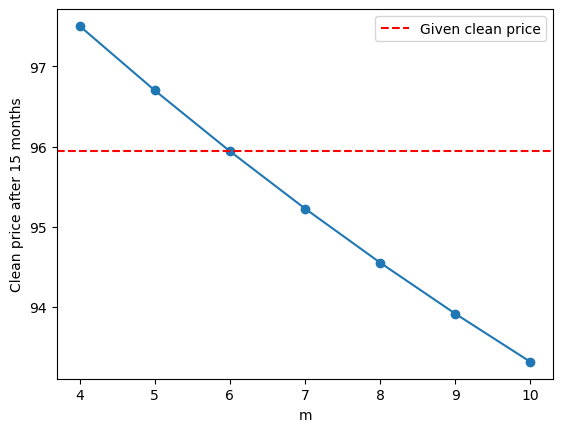

The clean price of the 6-year annual bond is 97.32698805053836 USD and the dirty price is 97.32698805053836
The clean price after 25 months is 96.58811620038388 USD


In [4]:
#Problem 2
#We consider a general n-period bond with n >= 4. 
F = 100
c = 0.05 #Annual
im = 0.06
CP_15 = 95.94321

#a) Find the bond price after 3 years. That is, find the dirty price
# We need to find the dirty price of the bond. We need to add the accrued interest (coupon) to the clean price
f_15 = 3/12
DP_15 = CP_15 + f_15 * c * F
print(f'The price of the bond is {DP_15} USD')
# We can calculate the maturity of the bond by plotting the clean price of different maturities
clean_prices = []
maturities = list(range(4, 11))
for m in maturities:
    coupons = sum(
        (F*c)/(1+im)**(k - 15/12) for k in range(2, m+1)
        )
    DP = coupons + F/(1+im)**(m-15/12)
    clean_prices.append(DP - F*c*f_15)
plt.plot(maturities, clean_prices, marker = "o")
plt.axhline(CP_15, color="red", linestyle="--", label="Given clean price")
plt.xlabel("m"); plt.ylabel("Clean price after 15 months"); plt.legend()
plt.show()

#The maturity of the bond is 6 years. Now we can calculate the price of the bond after 3 years. Then there are 3 years of coupons left
DP_3 = sum(
    (F*c)/(1+im)**(n-3)
    for n in range(4, 6+1)
) + F/(1+im)**(6-3)
#There is no accured coupons after 3 years.
f_3 = 0
CP_3 = DP_3 - f_3 * c * F
print(f'The clean price of the 6-year annual bond is {CP_3} USD and the dirty price is {DP_3}')

#b) We need to find the clean price of the bond after 25 months
DP_25 = sum(
    (F*c)/(1+im)**(k - 25/12) for k in range(3, 6+1)
) + F/(1+im)**(6 - 25/12)
f_25 = 1/12
CP_25 = DP_25 - f_25 * c * F
print(f'The clean price after 25 months is {CP_25} USD')

In [5]:
#Problem 3
T = 8
F = 800
m = 2
c = 0.04
i = 0.05 #effective annual yield of the bond

# Suppose that the bond price is lower after 3 years compared to the current price, what can we say aboud the yield of the bond?
#First we need to calculate the current price and then the price if the yield remained the same
P0 = sum(
    (F*c/m)/(1+i)**(k/m) for k in range(1, T*m+1)
) + F/(1+i)**(T)
print(f'The current price of the bond is {P0} USD')
# Now we consider the price if the yield would remain the same
P3 = sum(
    (F*c/m)/(1+i)**(k/m-3) for k in range(7, T*m+1)
) + F/(1+i)**(T-3)

print(
    f'The price of the bond would be {P3} if the yield would remain the same.\n' 
    'Since the price is higher and we know that the actual price is lower we can conclude that the yield at that time is higher')

The current price of the bond is 750.84805047099 USD
The price of the bond would be 767.0748547629797 if the yield would remain the same.
Since the price is higher and we know that the actual price is lower we can conclude that the yield at that time is higher


In [6]:
#Problem 4
spot_rates = {
    3: 0.015,
    6: 0.016,
    12: 0.02,
    18: 0.022,
    24: 0.023
}
# We consider a two-year bond with face value $1000. We need to find the annual effective yield rate. The bond's discount rate depends on the spot rate as it represents the opprtunity cost at that time
F = 1000
T = 2
c = 0.06
m = 1
P0 = (F*c)*(1/(1+spot_rates[12])**(1) + 1/(1+spot_rates[24])**(2)) + F/(1+spot_rates[24])**(2)
# we can define u = 1/(1+i), Then 0 = (c+1)u**2 + c*u - P0/F, We can use the abc formula to solve this
u1, u2= (-c + (c**2 + 4*(c+1)*P0/F)**(1/2)) / (2*(c+1)), (-c - (c**2 + 4*(c+1)*P0/F)**(1/2)) / (2*(c+1))
print(u1, u2)
print(f'The annual effective yield rate is {(1/u1 - 1) * 100}%')

#b) We should now quote the spot rates as annual nominal interest rates with m = 2 or m = infinity (for continuous compounding)
# We use s_t(0) = e^(i_infinity(t)) - 1 -> i_infinity(t) = ln(s_t(0) + 1)
# We use s_t(0) = (1 + i_2(t)/2)^2 - 1 -> ((s_t(0) + 1)^(1/2) - 1) * 2
def i_infinity(t):
    return math.log(spot_rates[t] + 1)

def i_2(t):
    return ((spot_rates[t] + 1) ** (1/2) - 1) * 2
print(f'The annual nominal interest rates using m = infinity and m = 2 are')

for t in spot_rates:
    print(f'i_infinity({t}) = {i_infinity(t)}, i_2({t}) = {i_2(t)}')


0.9775980018963424 -1.034201775481248
The annual effective yield rate is 2.291534767890502%
The annual nominal interest rates using m = infinity and m = 2 are
i_infinity(3) = 0.014888612493750559, i_2(3) = 0.01494416796098852
i_infinity(6) = 0.015873349156290163, i_2(6) = 0.015936506936664596
i_infinity(12) = 0.01980262729617973, i_2(12) = 0.01990098767241566
i_infinity(18) = 0.02176149178151271, i_2(18) = 0.02188031297601789
i_infinity(24) = 0.02273948696948934, i_2(24) = 0.022869249358445032


In [7]:
#Problem 5, Using the spot rates from Problem 4
T = 2
F = 500
c = 0.036
m = 2
#The price of the bond today is P0 and P1 in one year. After 1 year the spot rate are increased 0.2% uniformaly. Find P1-P0
coupon_times = [6, 12, 18, 24]
P0 = sum(
    (F*c/m)/(1+spot_rates[t]) ** (t/12) for t in coupon_times
) + F/(1+spot_rates[coupon_times[-1]]) ** (coupon_times[-1]/12)
print(P0)
spot_rates_new = {
    6: spot_rates[6] + 0.002,
    12: spot_rates[12] + 0.002
    }
P1 = (F*c/m)/(1+spot_rates_new[6])**(6/12) + (F*c/m + F)/(1+spot_rates_new[12])**(12/12) 
print(f'P1-P0 = {P1-P0}')


512.8330490247151
P1-P0 = -5.869918835419583


In [8]:
#Problem 6 a)
class Bond:
    def __init__(self, T, F, c, m, Price):
        self.T = T
        self.F = F
        self.c = c
        self.m = m
        self.Price = Price

Bond_A = Bond(1, 1000, 0, 2, 970.8738)
Bond_B = Bond(2, 1200, 0.03, 1, 1200) 
Bond_C = Bond(3, 1200, 0.05, 1, 1264.5347)
Bond_D = Bond(4, 1400, 0.03, 1, 1426.8603)

Bonds = [Bond_A, Bond_B, Bond_C, Bond_D]

spot_rates = {}
spot_rates[1] = Bond_A.F/Bond_A.Price - 1
for k in range(2, 4+1):
    b = Bonds[k-1]
    cpn = b.F * b.c / b.m
    pv_coupons = sum(
        cpn / (1 + spot_rates[t]) ** t for t in range(1, k)
    )
    spot_rates[k] =(((cpn + b.F)) / (b.Price - pv_coupons)) ** (1/k) - 1
print(spot_rates)



{1: 0.029999985580000166, 2: 0.030000000216299894, 3: 0.03100000091275268, 4: 0.024649280193799417}


In [9]:
#Problem 6 b)
class Bond:
    def __init__(self, T, F, c, m, Yield, price):
        self.T = T
        self.F = F
        self.c = c
        self.m = m
        self.Yield = Yield
        self.price = price

Bond_A = Bond(1, 1000, 0, None, 0.046, None)
Bond_B = Bond(2, 1000, 0.06, 1, 0.049, None) 
Bond_C = Bond(3, 1000, 0, None, 0.055, None)

#The yields are compute using continous compounding


Bonds = [Bond_A, Bond_B, Bond_C]

spot_rates = {}
spot_rates[1] = math.exp(Bonds[0].Yield) - 1
spot_rates[3] = math.exp(Bonds[2].Yield*3)**(1/3) - 1
print(f'The spot rates for t=1, 3 are {spot_rates[1]*100:.4f}% and {spot_rates[3]*100:.4f}%')
# For B we need to compute the price first. We use the e^-rt as the discount factor for continuous compounding
Bond_B.price = (Bond_B.F * Bond_B.c / Bond_B.m) * math.exp(-Bond_B.Yield*1) + (Bond_B.F * Bond_B.c / Bond_B.m + Bond_B.F) * math.exp(-Bond_B.Yield*2)
print(Bond_B.price)
#The price of the bond can be written with spot rates, Bond_B.price = cpn/(1+spot1)^1 + (cpn + F)/(1+spot2)^2
#We use the spot rate we calculated for Bond_A
spot_rates[2] = ((Bond_B.F + (Bond_B.F * Bond_B.c / Bond_B.m))/(Bond_B.price - (Bond_B.F * Bond_B.c / Bond_B.m) / (1 + spot_rates[1])**1))**(1/2)-1
print(f'The spot rate for 2 year zero coupon bond is {spot_rates[2]*100:.4f}%')

The spot rates for t=1, 3 are 4.7074% and 5.6541%
1018.1787057610665
The spot rate for 2 year zero coupon bond is 5.0314%


In [10]:
#Problem 7
term_structure = {}
for i in range(1, 21):
    term_structure[i/2] = 0
term_structure[0.5] = 0.025
#The bond pays semi-annually with face value F and redemption value C
#The annual nominal yield rate of a 10 year bond is 0.0249. We must calculate the annual effective yield rate of the 10 year bond
term_structure[10] = (1 + 0.0249/2)**2-1
print(term_structure[10])
#Since the annual effective yield for 10 years is greater than for the 0.5 year yield, the curve is upwards slooping


0.025055002500000256


In [11]:
# Problem 8
F = 100
T = 10
m = 1

c_A = 0.08
price_A = 105
c_B = 0.04
price_B = 95

#a) Using no arbitrage we should find the current price of a 10-year zero coupon bond with face value 200
# We should create a replicating portfolio using A and B that pays no coupons from year 1-10 and pays the face value of 200 at the end. 
# The price of the 10-year zero coupon bond must equal this replicating portfolio, otherwise there would be arbitrage
#To create a bond that pays no coupons we need to short 4 B-bonds and long 2 A-bond such that the net face value is 200
print(f'This will cost {4*price_B-2*price_A}')

#b) Find the cost of a 10-year zero coupon bond with face value 500 and 6% coupons rate
#We need to construct a portfolio with half a position in Bond_A and Bond_B. The coupon payments are 0.08*50 + 0.04 * 50 = 6 which is 6% of the face value
# We need 5 of them
# The price is
print(f'The price is {5*(price_A+price_B)/2}') 

This will cost 170
The price is 500.0


In [12]:
# Problem 9
T = 8
F = 100
c = 0.08
m = 2
i = 0.07

# The modified durations measures how sensitive the price is to changes in the yield. 
# D_mod = -(1/P) * dP/di
# The derivative with respect to i:
# P = sum(cpn*(1+i)^-t, 1<=t<=T ) + F(1+i)^-T
# dP/di = -sum(t*cpn*(1+i)^-(t+1), 1<=t<=T) + -T*F(1+i)^-(T+1)
cpn = F*c/m
p = sum(
    (cpn)/(1+i)**(t/2) for t in range(1, T*m+1)
) + F/(1+i)**(8)
print(p)
dp_di = -sum(
    t*cpn/(1+i)**(t/2+1) for t in range(1, T*m+1)
) + T*F/(1+i)**(T+1)
D_mod = -1/p * dp_di
print(D_mod)


106.79314129594488
-0.7642946271713946


In [13]:
#Problem 10
T = 12
F = 1200
c = 0.04
m = 2
n = T*m
i_m0 = 0.036 #Annual Nominal Yield
i_m1 = 0.044 #The new annual nominal yield

#First we need to convert to annual effective yields
def annual_effective_yield(i_m, m):
    annual_effective = (1+i_m/m)**m -1
    return annual_effective

i_0 = annual_effective_yield(i_m0, m)
i_1 = annual_effective_yield(i_m1, m)

#Calculate the bond price using the second order estimation
#First we should calculate the original price
coupons = F*c/m
P0 = sum(
    coupons/(1+i_0)**(k/m) for k in range(1, n+1)
) + F/(1+i_0)**T

#We should use the duration and the convexity

def d_mod(i, coupons, n):
    d_mod = 1/(1+i) * (sum(k/m * coupons/(1+i)**(k/m) for k in range(1, n+1)) + T*F/(1+i)**T)/(sum(coupons/(1+i)**(k/m) for k in range(1, n+1)) + F/(1+i)**T)
    return d_mod

def c_mod(i, coupons, n, P0):
    c_mod = (sum(k/m*(k/m+1)* coupons/(1+i)**(k/m) for k in range(1, n+1)) + (T*(T+1)*F/(1+i)**T))/((1+i)**2 * P0)
    return c_mod

def second_order_approx(i_0, i_1, P0):
    eps = i_1 - i_0
    P1 = P0 * (1 -eps * d_mod(i_0, coupons, n) + eps**2/2 * c_mod(i_0, coupons, n, P0))
    return P1
P1 = second_order_approx(i_0, i_1, P0)
P1_exact = sum(coupons/(1+i_1)**(k/m) for k in range(1, n+1)) + F/(1+i_1)**T
diff = (P1 - P1_exact)/P1_exact
print(f'The original price: {P0} \nThe approximated new price: {P1} \nThe exact price {P1_exact} \nPercentage error {diff*100:.4f}%')

The original price: 1246.438878150829 
The approximated new price: 1155.77406419085 
The exact price 1155.6184445339811 
Percentage error 0.0135%


In [14]:
# Example 9 from the lecture notes
F = 1000
T = 3
m = 1
eps = 0.01*30/100
def c_rate(i):
    return i + eps
bond_prices  = { #zero coupon bond price and their maturities
    0.5: 0.990148,
    1: 0.978474,
    2: 0.951814,
    3: 0.920493
}

#a) Calculate first coupon payment
i_1 = 1/bond_prices[1] - 1
c = c_rate(i_1)
coupon_1 = F*c #25 dollars

#b) Find the current price
#it is only equal to the face value if the coupon rate is equal to the interest rate which it is not in this case
# We must create a replicating portfolio. We can do this with a regular floating rate bond and 3 zero coupon bonds with maturity B(0,1) , B(0,2), B(0,3)

i_rates = {}

years = [1, 2, 3]

for k in list(bond_prices.keys()):
    i_rates[k] = 1/bond_prices[k] - 1
print(i_rates.values())
annuity = eps*F
price = F + sum(annuity*bond_prices[k] for k in years)
print(price)

dict_values([0.009950027672630757, 0.021999562584187338, 0.05062543732283831, 0.08637436677954091])
1008.552343


In [15]:
#Example 10
F = 1000
m = 2
T = 3
#Coupon rate is calculated based on the 6 month LIBOR rate
L_1 = 0.028
#After 3 months
L_rates = {
    1: 0.026,
    3: 0.0265,
    6: 0.027,
    12: 0.027
}

#The libor rates are quoted as annual nominal rates
c1 = F*L_1/2
print(c1)
#Calculate the bond price after 3 months
#This is between the dates of two coupon payments. We can create a replicating portfolio where we can the coupon for month 6 and the face value which is equal to pv of future payments
B_3 = 1/(1+L_rates[3]/2)**(1/2)
price = B_3*(F+c1)
price

14.0


1007.3482789702565

In [16]:
#Example 11


from MATH_4511_functions import Bond_fixed
L_rates = {
    1: 0.025,
    2: 0.025,
    3: 0.025,
    4: 0.025
}
F = 1000
c = 0.025
bondA = Bond_fixed(1000, 3, 1, 0.025, 0.025)
bondA.price()
spot_rates = [0.0225, 0.025, 0.0275]
for rate in spot_rates:
    price = bondA.price(rate)
    print(f' Rate: {rate} and the price of the fixed rate bond: {price:.6}')
# Next we calculate the price after 6 months
    B_6 = 1/(1+rate)**(1/2)
    price_6 = (price*c + price)*B_6
    print(f' Price after 6 months with rate {B_6}: {price_6}')

 Rate: 0.0225 and the price of the fixed rate bond: 1007.17
 Price after 6 months with rate 0.9889363528682975: 1020.9325091225992
 Rate: 0.025 and the price of the fixed rate bond: 1000.0
 Price after 6 months with rate 0.9877295966495897: 1012.4228365658299
 Rate: 0.0275 and the price of the fixed rate bond: 992.894
 Price after 6 months with rate 0.9865272473339801: 1004.0052578599248


In [17]:
#Example 11 (andra "Example 10" i föreläsningsanteckningarna, s. 56-58)
# Bond A: 3-årig obligation med fast kupong c = 2.5 % (årlig), F = 1000
# Bond B: 3-årig obligation med flytande kupong = 1-års LIBOR (årlig), F = 1000
# LIBOR-kurvan är flat på 2.5 % vid t = 0. Vi tittar på ett parallellskift till 2.25 %, 2.5 % och 2.75 %.
F, T, m, c = 1000, 3, 1, 0.025
L_0 = 0.025                       # 1-års LIBOR vid t = 0 (låser Bond B:s första kupong)
spot_rates = [0.0225, 0.025, 0.0275]

# a) Priser vid t = 0 när skiftet sker direkt vid emissionen.
#    För Bond B sätts även första kupongen om till den nya räntan, så priset blir alltid F.
print('Prices at t = 0')
for rate in spot_rates:
    bondA = Bond_fixed(F, T, m, c, rate)
    bondB = Bond_floating(F, m, [rate] * T, rate)
    print(f'  rate {rate:.4f}: Bond A (fixed) = {bondA.price():.4f}, Bond B (floating) = {bondB.price():.4f}')

# b) Priser efter 6 månader (t = 0.5). Första kupongen för Bond B låstes till L_0 = 2.5 % vid t = 0,
#    så bara diskonteringsräntan ändras. Termstrukturen antas fortfarande flat.
print('\nPrices at t = 0.5')
for rate in spot_rates:
    bondA = Bond_fixed(F, T, m, c, rate)
    bondB = Bond_floating(F, m, [L_0] * T, rate)
    print(f'  rate {rate:.4f}: Bond A (fixed) = {bondA.price(t=0.5):.4f}, Bond B (floating) = {bondB.price(t=0.5):.4f}')

# c) Macaulay-duration vid t = 0.5 med räntan 2.5 %. Bond B:s duration är tiden till nästa kupong.
bondA = Bond_fixed(F, T, m, c, L_0)
bondB = Bond_floating(F, m, [L_0] * T, L_0)
print(f'\nD_mac at t = 0.5: Bond A = {bondA.d_mac(t=0.5):.6f} years, Bond B = {bondB.d_mac(t=0.5):.6f} years')


Prices at t = 0
  rate 0.0225: Bond A (fixed) = 1007.1747, Bond B (floating) = 1000.0000
  rate 0.0250: Bond A (fixed) = 1000.0000, Bond B (floating) = 1000.0000
  rate 0.0275: Bond A (fixed) = 992.8943, Bond B (floating) = 1000.0000

Prices at t = 0.5
  rate 0.0225: Bond A (fixed) = 1018.4424, Bond B (floating) = 1013.6598
  rate 0.0250: Bond A (fixed) = 1012.4228, Bond B (floating) = 1012.4228
  rate 0.0275: Bond A (fixed) = 1006.4541, Bond B (floating) = 1011.1904

D_mac at t = 0.5: Bond A = 2.427424 years, Bond B = 0.500000 years


In [33]:
# Example 11
T = 2
S0 = 50
i = 0.02 #nominal annual yield compunded continously
X = S0 * math.exp(2*i) #The forward price of the asset

# Suppose that the 1-year spot rate is 1.9% after 1 year
# Calculate the value of the contract depending on the price of the asset at t=1
prices = [55, 47]

def f(price, B, X):
    f = price - X*B
    return f

# We need to calculate the forward rate from year 1 to 2
B_12 = math.exp(-0.019*1)

for p in prices:
    value = f(p, B_12, X)
    print(f'The value of the forward contract is {value}')



The value of the forward contract is 3.9388974181235668
The value of the forward contract is -4.061102581876433


In [ ]:
# Example 14
T = 18
F = 500
S_0 = 9

spot_rates_HKD = {
    6: 0.015,
    12: 0.015,
    18: 0.018,
    24: 0.02
}

spot_rates_EUR = {
    6: 0.02,
    12: 0.021,
    18: 0.021,
    24: 0.022
}

# The rates listed are annualized effective rates

S_6 = 8.8
# After 6 months the spot rates of HKD have increased uniformaly by 0.003 and decreased uniformaly by -0.001 for EUR
# Calculate the value of the forward contract
# First we need to calculate the delivery price which is done by setting the value of the contract at time 0 to 0
# We use the formula f_0 + X*B(0,T) = S_0*B_F(0,T). The values of the portfolios must be the same so we need to adjust with the exchange rate
# Here S0 denoted the value of the foreign currency in the home currency, ie the foreign exchange rate. We are basing this contract on one unit of currency
# X denotes the agreed upon exchange rate, B(0,T) and B_F(0,T) denotes the discount rates for the home and foreign currency

def B(t, rates, i):
    return 1/(1+rates[t] + i)**(t/12)

X = F*S_0 * B(18, spot_rates_EUR, 0) / B(18, spot_rates_HKD, 0)
print(X)

# Now we need to calculate the value of the contract f_t
f_6 = F * S_6 * B(12, spot_rates_EUR, -0.001) - X * B(12, spot_rates_HKD, 0.003) # We use 12 as there is only 12 months left until maturity
f_6

4480.181079740502


-87.23824235844313

In [43]:
# Example 15

#a) 

spot_rates = {
    6: 0.015,
    12: 0.015,
    18: 0.017,
    24: 0.0175,
    30: 0.0185,
    36: 0.02
}

# The rates of quoted as annual effective rates
# We want to calculate the 18 month forward rate starting in 6 months quoted as annual effective rate
dT = 18 #The difference expressed in number of years
T1 = 6
T2 = T1 + dT

def B(T):
    return 1/(1+spot_rates[T])**(T/12)
K = B(T1)/B(T2) - 1
f = (1+K)**(1/(dT/12))-1 #The difference expressed in number of years
print(f'The forward rate between month {T1} and {T2} is {f*100:.4}%') 

#b)

forward_rates_6 = { # The key denotes the starting time of the 6 month forward rate. They are annual effective rates
    0: 0.016,
    0.5: 0.016,
    1: 0.017,
    1.5: 0.0175,
    2: 0.018,
    2.5: 0.022
}

# We want to calculate the 2 year spot rate in effective rate
# The first step is to convert the forward rate to nominal terms, then reverse the formula to get B(2)
# We use (1+R_1)(1+K_1_2) = 1+R_2
# =(1+R_0.5)(1+K_0.5_1)(1+K_1_1.5)(1+K_1.5_2)
R_2 = (1+forward_rates_6[0])**(1/2) * (1+forward_rates_6[0.5])**(1/2) * (1+forward_rates_6[1])**(1/2) * (1+forward_rates_6[1.5])**(1/2) - 1

#(1+L_2)^2 = 1+R_2 -> L_2 = (1+R_2)^(1/2)-1
L_2 = (1+R_2)**(1/2)-1
L_2


The forward rate between month 6 and 24 is 1.833%


0.016624792530852917

In [47]:
# Example 17
T = 3
F = 500
c = 0.04 # annual payments
m = 1
# 1 year forward rate compunded continuously
f_1 = {
    0: 0.023,
    1: 0.023,
    2: 0.025,
    3: 0.026
}

def discount(t2, dt=1):
    discount_factor = math.exp(-f_1[t2-dt]*dt)
    return discount_factor

def discount_total(t2):
    if t2 == 0:
        return 1
    return discount(t2)*discount_total(t2-1)
    

# Calculate the current price of the bond
coupon = F*c
times = list(i for i in range(1, 3+1))
V0 = sum(
    coupon*discount_total(t) for t in times
) + F*discount_total(T)
print(V0)

523.0062728256277


In [ ]:
# Example 17 again with better time complexity

T = 3
F = 500
c = 0.04 # annual payments
m = 1
coupon = F*c
times = list(i for i in range(1, 3+1))
# 1 year forward rate compunded continuously
f_1 = {
    0: 0.023,
    1: 0.023,
    2: 0.025,
    3: 0.026
}

dis_tot_dict = {}

def discount(t2, dt=1):
    discount_factor = math.exp(-f_1[t2-dt]*dt)
    return discount_factor

price = 0
for t in times:
    if t == 1:
        dis_tot_dict[t] = discount(t)
    else:
        dis_tot_dict[t] = discount(t) * dis_tot_dict[t-1]
    price += coupon*dis_tot_dict[t] 
price += F*dis_tot_dict[T]
price


523.0062728256277